# Phase 4 — Race Prediction

**The question:** who finishes where?

This is the hardest phase, and not because the modelling is exotic. It is hard because the
dataset is small, the baseline is strong, and the features are built from *past races* — which
is the most leak-prone setup in the project.

**What you'll learn:**
1. Why 2,416 rows is small, and what that does to model choice
2. Why 'the race finishes in grid order' is a baseline worth respecting
3. **The `GROUPS` vs `ROWS` leak** — the subtlest bug here, demonstrated in one table
4. Why a random split is invalid for a *second*, worse reason than in Phase 2
5. Why Ridge beats XGBoost — the mirror image of Phase 2
6. Calibration: making '70%' actually mean 70%

In [1]:
import warnings, logging
warnings.filterwarnings('ignore')
logging.getLogger('fastf1').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from app.db.base import engine
from app.ml.prediction import dataset as ds, train as T

pd.set_option('display.width', 200)
df = ds.build_dataset(engine)
print(f'{len(df):,} driver-race rows | {df.event_id.nunique()} races | {df.driver.nunique()} drivers')
print(f'seasons: {sorted(df.season_year.unique())}')

2,416 driver-race rows | 121 races | 36 drivers
seasons: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


## 1. This is a small dataset

~24 races a year. Six seasons gives 121 races and 2,416 rows — and the rows inside a race are
strongly dependent, because only one car can win.

Compare that to Phase 2's 104,000 lap rows. Two orders of magnitude fewer, and it changes which
model wins.

In [2]:
print('For scale:')
print(f'  Phase 2 (tire degradation) : ~104,000 rows')
print(f'  Phase 4 (race prediction)  : {len(df):>8,} rows')
print()
print('And the features are not independent either:')
print(f'  rows per race        : {len(df)/df.event_id.nunique():.1f}')
print(f'  numeric features     : {len(ds.NUMERIC_FEATURES)}')
print(f'  rows per feature     : {len(df)/len(ds.NUMERIC_FEATURES):.0f}')
print()
print('One-hot encoding driver/team/circuit would add ~78 more columns to 2,416 rows.')
print('That is a 3% row-to-column ratio -- where a linear model starts memorising names.')

For scale:
  Phase 2 (tire degradation) : ~104,000 rows
  Phase 4 (race prediction)  :    2,416 rows

And the features are not independent either:
  rows per race        : 20.0
  numeric features     : 13
  rows per feature     : 186

One-hot encoding driver/team/circuit would add ~78 more columns to 2,416 rows.
That is a 3% row-to-column ratio -- where a linear model starts memorising names.


## 2. The baseline you have to beat

**'The race finishes in grid order.'** It sounds lazy. It is not — overtaking in modern F1 is
genuinely hard, so qualifying already contains most of the answer.

In [3]:
baselines = T.backtest_baselines(df, min_train_races=40)
print(f"{'baseline':<26}{'MAE':>8}{'rho':>9}{'top3':>8}{'top1':>8}")
print('-'*60)
for label, key in [('finish = grid order','baseline_grid'),
                   ('finish = recent form','baseline_driver_form')]:
    m = baselines[key]
    print(f"  {label:<24}{m['mae_positions']:>8.3f}{m['spearman']:>+9.3f}"
          f"{m['top3_hit_rate']:>8.1%}{m['top1_hit_rate']:>8.1%}")
print()
print('Grid order alone gets the winner right 44% of the time and rho +0.60.')
print('Any model that cannot beat this has learned nothing qualifying did not')
print('already tell you.')

baseline                       MAE      rho    top3    top1
------------------------------------------------------------
  finish = grid order        3.522   +0.604   59.7%   44.4%
  finish = recent form       3.777   +0.539   49.4%   35.8%

Grid order alone gets the winner right 44% of the time and rho +0.60.
Any model that cannot beat this has learned nothing qualifying did not
already tell you.


## 3. The leak — `GROUPS` vs `ROWS`

**This is the most important cell in the notebook.**

Every rolling feature uses a window frame ending at `1 PRECEDING`, so the current race cannot
enter its own feature. But the *frame type* matters just as much, and getting it wrong produces
no error at all.

- `ROWS` counts **physical rows**
- `GROUPS` counts **distinct ORDER BY values**, treating ties as one peer group

For a driver-level window they agree — one row per driver per race. For a **team**-level window
they do not, because a team has two cars in every race.

In [4]:
ferrari = pd.read_sql(text('''
    WITH results AS (
      SELECT e.event_date, e.round, d.abbreviation AS driver, t.name AS team,
             sr.position::float AS finish
      FROM raw.session_results sr
      JOIN raw.sessions s ON s.id=sr.session_id AND s.session_type='R'
      JOIN raw.events e ON e.id=s.event_id
      JOIN raw.drivers d ON d.id=sr.driver_id
      LEFT JOIN raw.teams t ON t.id=sr.team_id
      WHERE sr.position IS NOT NULL AND t.name='Ferrari' AND e.season_year=2024)
    SELECT round, driver, finish,
      round(avg(finish) OVER (PARTITION BY team ORDER BY event_date
            ROWS BETWEEN 3 PRECEDING AND 1 PRECEDING)::numeric,2)   AS rows_frame,
      round(avg(finish) OVER (PARTITION BY team ORDER BY event_date
            GROUPS BETWEEN 3 PRECEDING AND 1 PRECEDING)::numeric,2) AS groups_frame
    FROM results WHERE round <= 4 ORDER BY round, driver
'''), engine)
print('Ferrari, 2024, team form going INTO each race:\n')
print(ferrari.to_string(index=False))

Ferrari, 2024, team form going INTO each race:

 round driver  finish  rows_frame  groups_frame
     1    LEC     4.0         NaN           NaN
     1    SAI     3.0        4.00           NaN
     2    BEA     7.0        3.33          3.50
     2    LEC     3.0        3.50          3.50
     3    LEC     2.0        4.33          4.25
     3    SAI     1.0        4.00          4.25
     4    LEC     4.0        3.33          3.33
     4    SAI     3.0        2.33          3.33


Read that table carefully. Two things are wrong with the `ROWS` column:

**1. Round 1, SAI = 4.00.** That is Leclerc's finishing position *in round 1* — a race that had
not happened yet when the feature was supposedly measured. `GROUPS` correctly gives NULL: there
is no previous race.

**2. Rounds 3 and 4 give the two teammates DIFFERENT values.** A team-level feature computed
over previous races *must* be identical for both of a team's cars. If they disagree, the window
reached into the current race.

That second point is the useful tell, because checking it requires no knowledge of window
functions at all. It is just: *are these two numbers the same?*

In [5]:
print('The audit runs that check over the WHOLE dataset:\n')
report = ds.audit_leakage(df)
for k, v in report.items(): print(f'  {k:<40} {v}')
print()
print('`train_all` runs this BEFORE training and refuses to proceed if it fails.')
print('An advisory leakage check gets ignored.')

The audit runs that check over the WHOLE dataset:

  teammate_team_form_disagreements         0
  first_race_rows                          36
  first_race_with_form                     0
  passes                                   True

`train_all` runs this BEFORE training and refuses to proceed if it fails.
An advisory leakage check gets ignored.


## 4. Why a random split is invalid — twice over

Phase 2's reason applies: rows inside a race are dependent, so a random split puts the same race
on both sides.

But there is a **second, worse reason** specific to this phase. The features are built *from past
races*. Train on a 2024 race and test on a 2023 one, and the training row's features were
computed from data that includes the test row's race.

**The leak runs backwards through the feature construction.** No amount of row shuffling fixes
that — the features themselves are already contaminated.

So evaluation is walk-forward: train on everything before race N, predict race N, step forward.

In [6]:
splits = ds.walk_forward_splits(df, min_train_races=40)
print(f'{len(splits)} walk-forward folds\n')
print(f"{'fold':>5}{'train races':>13}{'train rows':>12}{'test race':>26}")
for i in (0, 1, len(splits)//2, len(splits)-1):
    tr, te = splits[i]
    ev = te.iloc[0]
    print(f'{i:>5}{tr.event_id.nunique():>13}{len(tr):>12}'
          f"   {int(ev.season_year)} R{int(ev['round']):02d} {ev.circuit:<16}")
print()
print('Every training set ends strictly BEFORE its test race. The early folds')
print('train on very little, which makes this strictly harder than a season')
print('holdout -- and closer to how the model would really be used.')

81 walk-forward folds

 fold  train races  train rows                 test race
    0           40         800   2021 R03 Portimão        
    1           41         820   2021 R04 Barcelona       
   40           80        1598   2023 R06 Monaco          
   80          120        2396   2024 R24 Yas Island      

Every training set ends strictly BEFORE its test race. The early folds
train on very little, which makes this strictly harder than a season
holdout -- and closer to how the model would really be used.


## 5. Ridge beats the boosters

Phase 2 had 104,000 rows and XGBoost won. Here the order is reversed, and deliberately so: Ridge
first, then a shallow forest, then XGBoost third.

This takes a minute — 81 folds × 3 models.

In [7]:
import time
results = {}
print(f"{'model':<18}{'MAE':>8}{'rho':>9}{'top3':>8}{'top1':>8}{'vs grid':>10}{'fit':>8}")
print('-'*71)
grid = baselines['baseline_grid']
print(f"  {'baseline: grid':<16}{grid['mae_positions']:>8.3f}{grid['spearman']:>+9.3f}"
      f"{grid['top3_hit_rate']:>8.1%}{grid['top1_hit_rate']:>8.1%}")
for label, builder in T.MODEL_BUILDERS.items():
    t0 = time.perf_counter()
    m, preds = T.walk_forward_backtest(builder, df, min_train_races=40)
    results[label] = (m, preds)
    print(f"  {label:<16}{m['mae_positions']:>8.3f}{m['spearman']:>+9.3f}"
          f"{m['top3_hit_rate']:>8.1%}{m['top1_hit_rate']:>8.1%}"
          f"{1-m['mae_positions']/grid['mae_positions']:>+9.1%}{time.perf_counter()-t0:>7.0f}s")

model                  MAE      rho    top3    top1   vs grid     fit
-----------------------------------------------------------------------
  baseline: grid     3.522   +0.604   59.7%   44.4%


  ridge              3.136   +0.677   66.3%   56.8%   +11.0%      1s


  random_forest      3.218   +0.676   60.1%   54.3%    +8.6%     21s


  xgboost            3.226   +0.671   61.3%   54.3%    +8.4%     11s


**Ridge wins.** On 104,000 rows a gradient booster was best; on 2,416 a regularised linear
model is. The amount of data decides the model, not the model's reputation.

And the improvement is **modest** — around 11% on MAE. That is the honest characterisation of
this problem, not a disappointment. Qualifying already contains most of the signal; the model
adds form, reliability and circuit history on top.

In [8]:
# Does one-hot encoding driver/team/circuit help? Measure, do not assume.
print('Adding ~78 identity columns to 2,416 rows:\n')
print(f"{'model':<18}{'without':>10}{'with':>10}{'change':>10}")
for label, builder in T.MODEL_BUILDERS.items():
    a, _ = T.walk_forward_backtest(builder, df, include_identity=False, min_train_races=60)
    b, _ = T.walk_forward_backtest(builder, df, include_identity=True, min_train_races=60)
    print(f"  {label:<16}{a['mae_positions']:>10.3f}{b['mae_positions']:>10.3f}"
          f"{b['mae_positions']-a['mae_positions']:>+10.3f}")
print()
print('Consistently WORSE. The rolling features already carry it: driver_form_3')
print('encodes "is this driver fast right now" better than a driver dummy, and')
print('it generalises to a driver the model has never seen.')

Adding ~78 identity columns to 2,416 rows:

model                without      with    change


  ridge                3.094     3.130    +0.036


  random_forest        3.174     3.178    +0.003


  xgboost              3.193     3.209    +0.016

Consistently WORSE. The rolling features already carry it: driver_form_3
encodes "is this driver fast right now" better than a driver dummy, and
it generalises to a driver the model has never seen.


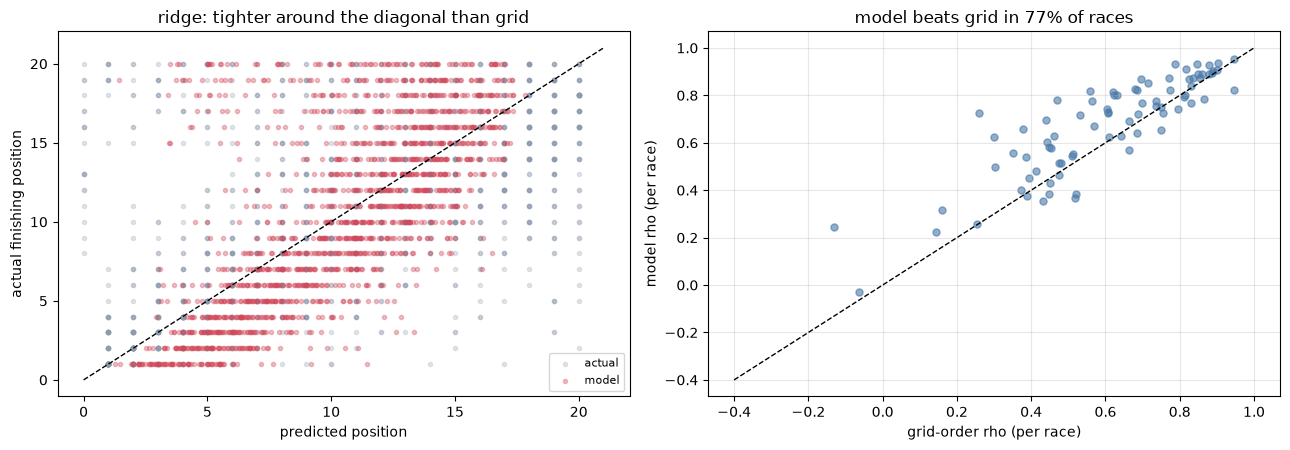

Above the dashed line = the model ordered that race better than the grid did.


In [9]:
best_label = min(results, key=lambda k: results[k][0]['mae_positions'])
preds = results[best_label][1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
ax.scatter(preds.grid_position, preds.finish_position, s=9, alpha=0.25,
           color='#8d99ae', label='actual')
ax.scatter(preds.predicted, preds.finish_position, s=9, alpha=0.35,
           color='#d1495b', label='model')
lim = [0, 21]; ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel('predicted position'); ax.set_ylabel('actual finishing position')
ax.set_title(f'{best_label}: tighter around the diagonal than grid'); ax.legend(fontsize=8)

ax = axes[1]
per_race = []
for eid, g in preds.groupby('event_id'):
    from scipy.stats import spearmanr
    r_model,_ = spearmanr(g.predicted, g.finish_position)
    r_grid,_  = spearmanr(g.grid_position, g.finish_position)
    if not (np.isnan(r_model) or np.isnan(r_grid)): per_race.append((r_grid, r_model))
pr = pd.DataFrame(per_race, columns=['grid','model'])
ax.scatter(pr.grid, pr.model, s=26, alpha=0.6, color='#4878a8')
ax.plot([-0.4,1],[-0.4,1],'k--',lw=1)
ax.set_xlabel('grid-order rho (per race)'); ax.set_ylabel('model rho (per race)')
ax.set_title(f'model beats grid in {(pr.model>pr.grid).mean():.0%} of races')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Above the dashed line = the model ordered that race better than the grid did.')

## 6. Calibration — making '70%' mean 70%

A separate classifier predicts P(podium). **Podium, not win**: there are ~360 podium finishes
against ~121 wins, so three times the positive class. Predicting wins from 121 examples is not a
modelling problem, it is a wish.

A model can rank well and still be badly calibrated, and a miscalibrated probability is dangerous
to act on. Brier score alone will not reveal it — a calibration table will.

In [10]:
from sklearn.metrics import brier_score_loss
frames = []
for tr, te in ds.walk_forward_splits(df, min_train_races=40):
    clf = T.build_podium_classifier()
    clf.fit(ds.feature_matrix(tr), tr[ds.TARGET_PODIUM].astype(int))
    frames.append(te.assign(p=clf.predict_proba(ds.feature_matrix(te))[:,1]))
pod = pd.concat(frames, ignore_index=True)
y = pod[ds.TARGET_PODIUM].astype(int).to_numpy(); p = pod.p.to_numpy()

brier = brier_score_loss(y, p); base = y.mean()
brier_base = float(np.mean((base - y)**2))
print(f'Brier {brier:.4f}   vs always-predict-{base:.2f}: {brier_base:.4f}'
      f'   skill {1-brier/brier_base:+.1%}\n')
print(T.calibration_table(p, y).assign(
    predicted=lambda d: d.predicted.round(2), observed=lambda d: d.observed.round(2)
).to_string(index=False))

Brier 0.0694   vs always-predict-0.15: 0.1278   skill +45.6%

       bucket    n  predicted  observed
(-0.001, 0.2] 1197       0.03      0.02
   (0.2, 0.4]  155       0.29      0.33
   (0.4, 0.6]  114       0.50      0.50
   (0.6, 0.8]   93       0.70      0.71
   (0.8, 1.0]   57       0.87      0.82


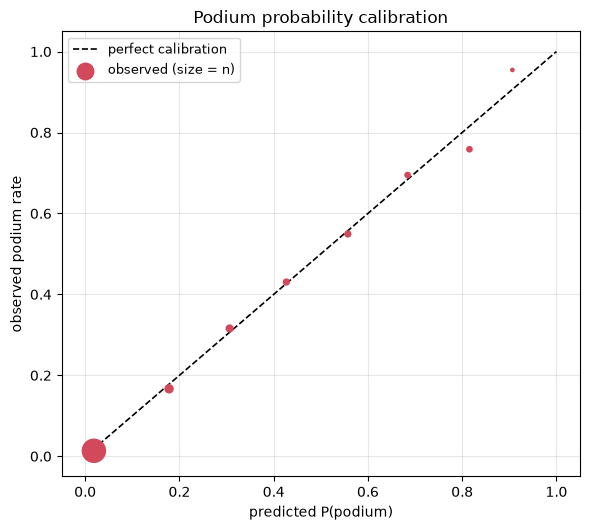

Points on the diagonal mean the probability is honest: when the model says
70%, it happens about 70% of the time. That is what makes it safe to act on.


In [11]:
fig, ax = plt.subplots(figsize=(6,5.4))
tbl = T.calibration_table(p, y, bins=8)
ax.plot([0,1],[0,1],'k--',lw=1.2,label='perfect calibration')
ax.scatter(tbl.predicted, tbl.observed, s=tbl.n/4, color='#d1495b', zorder=3,
           label='observed (size = n)')
ax.set_xlabel('predicted P(podium)'); ax.set_ylabel('observed podium rate')
ax.set_title('Podium probability calibration'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Points on the diagonal mean the probability is honest: when the model says')
print('70%, it happens about 70% of the time. That is what makes it safe to act on.')

---

## What Phase 4 established

| # | Finding |
|---|---|
| 1 | 2,416 rows across 121 races — **small**, and correlated within races |
| 2 | 'Finish = grid order' gets the winner right 44% of the time (rho +0.60). A baseline to respect |
| 3 | **`GROUPS` not `ROWS`**: with `ROWS`, a team feature reads the driver's own teammate in the race being predicted |
| 4 | The tell is structural — two teammates getting *different* team-form values |
| 5 | A random split is invalid for a **second** reason: the leak runs backwards through feature construction |
| 6 | **Ridge wins** (MAE 3.136 vs XGBoost 3.226). The mirror image of Phase 2 |
| 7 | +11.0% over the grid baseline — modest and real |
| 8 | Identity columns make every model *worse*; the rolling features already carry that signal |
| 9 | Podium probability is well calibrated: +45.6% Brier skill, predicted 0.70 → observed 0.71 |

**The transferable lesson:** leakage produces no error. No exception, no warning — just a model
that looks better than it is. The defences that worked here were *declarative* (a `1 PRECEDING`
frame), *structural* (two teammates must agree), and *enforced* (training refuses to run if the
audit fails). Not vigilance.

**And the recurring one, now four phases deep:** the amount of data decides the model. Phase 2
at 104k rows rewarded a booster; Phase 4 at 2.4k punishes one.

**Next:** `/api/v1/dashboard/*` serves all of this — see `docs/phase5-dashboard.md`.